# Faixa dividida · split-range

**Um comando. Primeiro uso a água quente; quando ela não basta, entra o aquecedor.**

Vou controlar a temperatura de um ambiente. O diferencial está em decidir
qual recurso usar, mantendo um único PI. Execute de cima para baixo.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as controles
from scipy.optimize import curve_fit
from IPython.display import display

plt.rcParams.update({"figure.figsize": (9, 3), "axes.grid": True,
                     "grid.alpha": 0.2, "font.size": 10})

## O processo

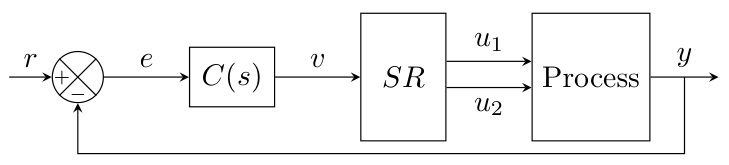

Uso dois canais térmicos publicados, com a temperatura externa fixa em 17 °C:

$$G_{agua}(s)=\frac{12e^{-3s}}{10s+1},\qquad
G_{eletrico}(s)=\frac{8e^{-s}}{5s+1}.$$

A entrada vai de 0 a 1; a saída é o aumento de temperatura em °C; o tempo está em minutos.
Com água quente sozinha, a temperatura chega no máximo a 29 °C nesse modelo.
Com os dois recursos, chega a 37 °C.

In [2]:
nomes = ['Água quente', 'Aquecedor elétrico']
modelos = np.array([[12.0, 10.0, 3.0], [8.0, 5.0, 1.0]])  # K, τ, θ
temperatura_externa = 17.0
unidade_tempo = 'Tempo (min)'
unidade_saida = 'Aumento de temperatura (°C)'

## Primeiro, repartir o comando

Até 60%, abro somente a água quente. Acima disso, ela fica totalmente aberta
e o aquecedor começa a atuar. Essa divisão iguala os ganhos estáticos nas duas faixas.
Mova o comando e veja as aberturas.

In [3]:
def dividir_comando(comando, ponto_divisao=0.60):
    agua = np.clip(comando / ponto_divisao, 0, 1)
    eletrico = np.clip((comando - ponto_divisao) / (1 - ponto_divisao), 0, 1)
    return np.array([agua, eletrico])

def ver_aberturas(comando=40):
    aberturas = dividir_comando(comando / 100)
    figura, eixo = plt.subplots(figsize=(7, 2.4))
    eixo.barh(nomes, 100 * aberturas, color=['#2374ab', '#df752c'])
    eixo.set(xlim=(0, 100), xlabel='Abertura (%)', title=f'Comando único: {comando}%')
    plt.show()

display(controles.interactive(ver_aberturas, comando=controles.IntSlider(
    value=40, min=0, max=100, step=5, description='Comando', continuous_update=False)))

interactive(children=(IntSlider(value=40, continuous_update=False, description='Comando', step=5), Output()), …

## Identificar com ruído

Testo cada recurso separadamente com um degrau e ruído de medição.
São dados simulados; vou tratá-los como um ensaio de identificação.
Estimo ganho, constante de tempo e atraso a partir das curvas.

In [4]:
def resposta_modelo(tempo, entrada, parametros):
    ganho, constante, atraso = parametros
    variacoes = np.diff(entrada, prepend=0)
    saida = np.zeros_like(tempo)
    for indice in np.flatnonzero(variacoes):
        decorrido = np.maximum(tempo - tempo[indice] - atraso, 0)
        saida += ganho * variacoes[indice] * (1 - np.exp(-decorrido / constante))
    return saida

In [5]:
tempo_ensaio = np.arange(0, 160.1, 0.5)
entrada_ensaio = np.where(tempo_ensaio >= 5, 0.25, 0.0)  # Aplico 25% em um recurso por vez.
desvio_ruido = 0.08
gerador = np.random.default_rng(43)
medicoes_ensaio = np.array([resposta_modelo(tempo_ensaio, entrada_ensaio, modelo)
                           + gerador.normal(0, desvio_ruido, len(tempo_ensaio))
                           for modelo in modelos])

In [6]:
def identificar(tempo, entrada, medicao):
    def previsao(tempo, ganho, constante, atraso):
        return resposta_modelo(tempo, entrada, [ganho, constante, atraso])
    parametros, _ = curve_fit(previsao, tempo, medicao,
                             p0=[1, 8, 1], bounds=([0.001, 0.1, 0], [100, 60, 10]))
    return parametros

estimativas = np.array([identificar(tempo_ensaio, entrada_ensaio, medicao)
                       for medicao in medicoes_ensaio])
for nome, valores in zip(nomes, estimativas):
    print(f"{nome}: K={valores[0]:.3f}; τ={valores[1]:.2f}; θ={valores[2]:.2f}")

Água quente: K=12.012; τ=10.14; θ=3.02
Aquecedor elétrico: K=7.975; τ=4.89; θ=0.98


## Validar em outro ensaio

Reservo uma sequência diferente e novas medições ruidosas. Uso os parâmetros
estimados sem ajustá-los novamente. Observe se o modelo acompanha tanto a subida
quanto a queda. O RMSE está em °C.

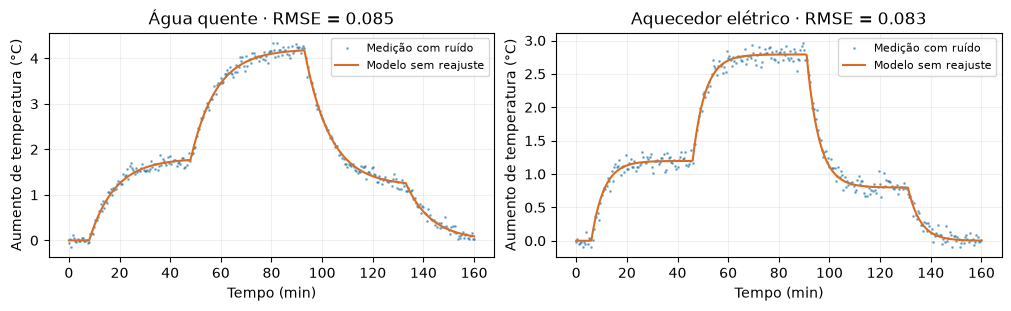

In [7]:
entrada_validacao = np.select([tempo_ensaio < 5, tempo_ensaio < 45,
                                  tempo_ensaio < 90, tempo_ensaio < 130],
                                 [0, 0.15, 0.35, 0.10], default=0).astype(float)

gerador_validacao = np.random.default_rng(2026)
medicoes_validacao = np.array([resposta_modelo(tempo_ensaio, entrada_validacao, modelo)
                             + gerador_validacao.normal(0, desvio_ruido, len(tempo_ensaio))
                             for modelo in modelos])
previsoes_validacao = np.array([resposta_modelo(tempo_ensaio, entrada_validacao, parametros)
                              for parametros in estimativas])
erros_validacao = medicoes_validacao - previsoes_validacao
rmse_validacao = np.sqrt(np.mean(erros_validacao ** 2, axis=1))

figura, eixos = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
for nome, medicao, previsao, rmse, eixo in zip(
        nomes, medicoes_validacao, previsoes_validacao, rmse_validacao, eixos):
    eixo.plot(tempo_ensaio, medicao, '.', ms=2, alpha=0.5, label='Medição com ruído')
    eixo.plot(tempo_ensaio, previsao, color='#db6b20', label='Modelo sem reajuste')
    eixo.set(title=f'{nome} · RMSE = {rmse:.3f}', xlabel=unidade_tempo,
             ylabel=unidade_saida)
    eixo.legend(fontsize=8)
plt.show()

## Sintonia IMC

A divisão será calculada pelas estimativas: $p=K_agua/(K_agua+K_eletrico)$.
Assim, o ganho de cada faixa fica $K_agua+K_eletrico$.
Para o PI único, adoto a dinâmica mais lenta como aproximação de projeto:
$\tau=\max(\tau_i)$, $\theta=\max(\theta_i)$.

In [8]:
def sintonia_imc(parametros, tempo_resposta):
    ganho, constante, atraso = parametros
    ganho_controlador = constante / (ganho * (tempo_resposta + atraso))
    tempo_integral = constante
    return ganho_controlador, tempo_integral

def comando_pi(erro, integral, ganho, tempo_integral, passo):
    tentativa = ganho * erro + integral
    comando = np.clip(tentativa, 0, 1)
    # Não acumulo integral quando ela empurra além do limite.
    if 0 < tentativa < 1 or (tentativa >= 1 and erro < 0) or (tentativa <= 0 and erro > 0):
        integral += ganho * erro * passo / tempo_integral
    return comando, integral

ganho_equivalente = estimativas[:, 0].sum()
ponto_divisao = estimativas[0, 0] / ganho_equivalente
modelo_projeto = np.array([ganho_equivalente, estimativas[:, 1].max(),
                          estimativas[:, 2].max()])
print(f'Divisão estimada: {100 * ponto_divisao:.1f}%')
print('Kc e Ti do PI único:', np.round(sintonia_imc(modelo_projeto, 12), 3))

Divisão estimada: 60.1%
Kc e Ti do PI único: [ 0.034 10.144]


## A simulação

Comparo água quente sozinha com os dois recursos. A referência muda em 10 min.
O divisor e o PI usam as estimativas; a planta usa os modelos publicados.
A aproximação da sintonia não iguala a dinâmica dos recursos.

In [9]:
def simular_faixa(referencia=33, tempo_resposta=12, dois_recursos=True, passo=0.05):
    tempo = np.arange(0, 240 + passo / 2, passo)
    temperatura = np.full(len(tempo), temperatura_externa)
    aberturas = np.zeros((len(tempo), 2))
    comandos = np.zeros(len(tempo))
    contribuicoes = np.zeros(2)
    integral = 0.0
    ganho, tempo_integral = sintonia_imc(modelo_projeto, tempo_resposta)
    atenuacoes = np.exp(-passo / modelos[:, 1])
    atrasos = np.rint(modelos[:, 2] / passo).astype(int)
    for indice in range(len(tempo) - 1):
        desejada = referencia if tempo[indice] >= 10 else temperatura_externa
        limite = 1 if dois_recursos else ponto_divisao
        erro = desejada - temperatura[indice]
        tentativa = ganho * erro + integral
        comandos[indice] = np.clip(tentativa, 0, limite)
        # Só integro se o limite não impedir a correção pedida.
        if 0 < tentativa < limite or (tentativa >= limite and erro < 0) or (tentativa <= 0 and erro > 0):
            integral += ganho * erro * passo / tempo_integral
        aberturas[indice] = dividir_comando(comandos[indice], ponto_divisao)
        for canal in range(2):
            anterior = indice - atrasos[canal]
            atrasado = aberturas[max(anterior, 0), canal]
            contribuicoes[canal] = (atenuacoes[canal] * contribuicoes[canal]
                                    + (1 - atenuacoes[canal]) * modelos[canal, 0] * atrasado)
        temperatura[indice + 1] = temperatura_externa + contribuicoes.sum()
    aberturas[-1] = aberturas[-2]
    comandos[-1] = comandos[-2]
    return tempo, temperatura, aberturas, comandos

In [10]:
def explorar_faixa(referencia=33, tempo_resposta=12):
    tempo, temperatura, aberturas, _ = simular_faixa(referencia, tempo_resposta, True)
    _, so_agua, _, _ = simular_faixa(referencia, tempo_resposta, False)
    figura, eixos = plt.subplots(2, 1, figsize=(9, 5), sharex=True, constrained_layout=True)
    eixos[0].plot(tempo, so_agua, label='Só água quente', color='#888888')
    eixos[0].plot(tempo, temperatura, label='Faixa dividida', color='#2374ab')
    eixos[0].plot(tempo, np.where(tempo >= 10, referencia, temperatura_externa),
                  ls='--', color='#555555', label='Referência')
    eixos[0].set(ylabel='Temperatura (°C)', title='Mais capacidade com o segundo recurso')
    eixos[0].legend(fontsize=8)
    eixos[1].plot(tempo, 100 * aberturas[:, 0], label='Água quente')
    eixos[1].plot(tempo, 100 * aberturas[:, 1], label='Aquecedor elétrico')
    eixos[1].set(xlabel='Tempo (min)', ylabel='Abertura (%)', ylim=(-3, 103))
    eixos[1].legend(fontsize=8)
    plt.show()
    limite = temperatura_externa + modelos[:, 0].sum()
    print(f'Limite com os dois recursos: {limite:.0f} °C · temperatura final: {temperatura[-1]:.2f} °C')

painel_faixa = controles.interactive(
    explorar_faixa,
    referencia=controles.IntSlider(value=33, min=22, max=39, step=1,
                                   description='Referência (°C)', continuous_update=False),
    tempo_resposta=controles.IntSlider(value=12, min=8, max=24, step=2,
                                       description='IMC λ (min)', continuous_update=False))
display(painel_faixa)

interactive(children=(IntSlider(value=33, continuous_update=False, description='Referência (°C)', max=39, min=…

## O que observar

- **Referência:** abaixo de 29 °C, a água pode bastar; acima disso, entra o aquecedor.
- **IMC λ:** valores maiores tornam a resposta mais lenta e a atuação menos brusca.
- **Teste 39 °C:** os dois saturam. A faixa dividida não cria capacidade que o processo não tem.

Usar os dois recursos aumenta a faixa atendida; uma sintonia única exige compromisso
entre suas dinâmicas. A teoria e as referências estão no [README](https://github.com/The-Celestino/toolbox-controle-classico/blob/main/estrategias/04_split_range/README.md).

## Referências

1. Luna, J. D. F. O. et al. (2024). *A model predictive control interpretation of the generalized
split-range control*. CBA 2024, 1249–1254.
[Artigo](https://doi.org/10.20906/CBA2024/4340), seção 4 e Tabela 1. Imagem: Figura 1, p. 1249.
A aplicação aqui usa os modelos térmicos para estudar o divisor clássico; não reproduz MPC/GSRC.
2. Longhi, L. G. S. (2017). *Uma heurística fundamental — e normalmente esquecida — para o projeto
de sistemas de controle: justificativa e exemplos industriais*. Revista Técnica da UP, 1(4), 36–75.
[Artigo](https://rtup.petrobras.com.br/rtup/article/download/34/40/64).
3. Rivera, D. E.; Morari, M.; Skogestad, S. (1986). *Internal model control. 4. PID controller design*.
[DOI](https://doi.org/10.1021/i200032a041).